In [1]:
import os 
from typing import TypedDict,Annotated
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import StateGraph , START , END
from langgraph.checkpoint.memory import MemorySaver

In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
model = llm = ChatDeepSeek(model="deepseek-chat")

In [5]:
class MyAgent(TypedDict):
    user: str
    ai: str
    

In [7]:
def draft_node(state: MyAgent):
    prompt=f"Explain brirfly what {state['user']} is in 2 sentences"
    res=llm.invoke(prompt)
    return{'ai':res.content}

In [9]:
def summury_node(state:MyAgent):
    prompt=f"toold key point in {state['ai']}"
    res=llm.invoke(prompt)
    
    return{'ai':state['ai']+ "\n\nTip:"+res.content}


In [11]:
grap=StateGraph(MyAgent)

grap.add_node("draft",draft_node)
grap.add_node("summ",summury_node)

grap.add_edge(START,"draft")
grap.add_edge("draft","summ")
grap.add_edge("summ",END)

In [13]:
memory=MemorySaver()
app=grap.compile(checkpointer=memory)

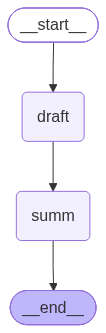

In [14]:
app

In [16]:
config={"configurable":{"thread_id": "session_01"}}
inputs = {"user": "gen ai"}

print("=== স্ট্রিমিং শুরু হচ্ছে ===\n")

# ৩. টোকেন-বাই-টোকেন লাইভ রান করার লুপ
async for event in app.astream_events(inputs, config=config, version="v2"):
    kind = event["event"]
    
    # নোড শুরু হলে নোডের নাম দেখাবে
    if kind == "on_node_start":
        node_name = event["name"]
        print(f"\n\n--- [চলছে: {node_name}] ---")
        
    # LLM থেকে টোকেন আসার সাথে সাথে টাইপরাইটারের মতো স্ক্রিনে প্রিন্ট হবে
    elif kind == "on_chat_model_stream":
        chunk = event["data"]["chunk"]
        if chunk.content:
            print(chunk.content, end="", flush=True)

print("\n\n=== সফলভাবে সম্পন্ন হয়েছে ===")

=== স্ট্রিমিং শুরু হচ্ছে ===

Generative AI is a type of artificial intelligence that creates new content—such as text, images, audio, or code—by learning patterns from large amounts of existing data. Instead of just analyzing or classifying information, it produces original outputs in response to prompts.That's a solid summary. Here's a slightly tightened version if you want it as a clean key point:

**Key Point:**
Generative AI is a type of artificial intelligence that creates new content—such as text, images, audio, or code—by learning patterns from large amounts of existing data. Rather than only analyzing or classifying information, it generates original outputs in response to prompts.

A few extra nuances worth noting if you're expanding this:

- **How it works:** It typically relies on models like transformers, GANs, or diffusion models trained on massive datasets.
- **Core distinction:** Discriminative AI *labels* or *predicts*; generative AI *produces*.
- **Key enabler:** Scal